Создан детектор с 40 ФЭУ.
Координаты первых 3-х ФЭУ:
[[ 0.16104292 -0.41420427  1.95      ]
 [-0.68149594  0.33624883  1.85      ]
 [ 0.92965601  0.27062835  1.75      ]]


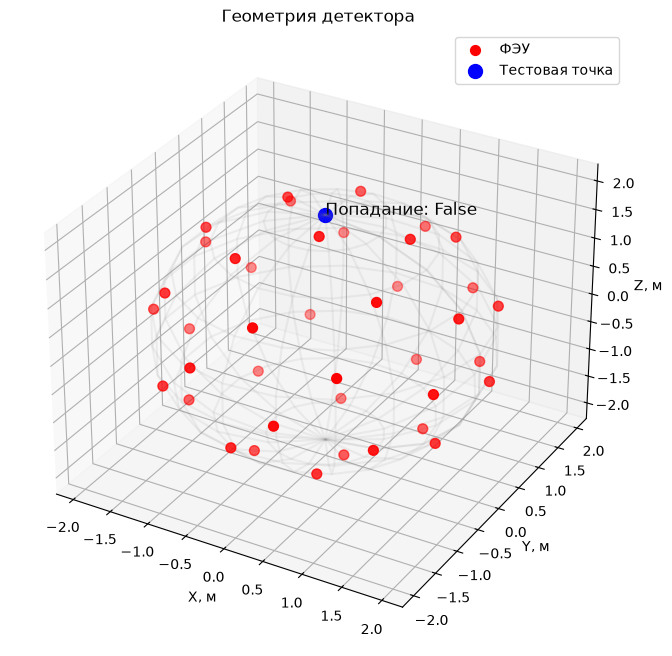

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        """
        R - радиус детектора (м)
        N - количество фотоумножителей
        r - радиус фотокатода (м)
        a - вероятность выбивания фотоэлектрона
        """
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        
        # Генерируем координаты ФЭУ равномерно по сфере (спираль Фибоначчи)
        indices = np.arange(0, N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / N)  # полярный угол от 0 до pi
        theta = np.pi * (1 + 5**0.5) * indices  # азимутальный угол (золотое сечение)
        
        # Переводим в декартовы координаты и умножаем на радиус
        x = np.cos(theta) * np.sin(phi) * R
        y = np.sin(theta) * np.sin(phi) * R
        z = np.cos(phi) * R
        
        # Сохраняем координаты ФЭУ в виде массива (N, 3) - это и есть "подходящая структура"
        self.pmt_positions = np.column_stack((x, y, z))

    def is_hit(self, point):
        """
        Проверяет, принадлежит ли точка на поверхности детектора 
        какому-либо фотоумножителю.
        point: np.array([x, y, z])
        """
        # Считаем расстояние от точки до центров всех ФЭУ
        distances = np.linalg.norm(self.pmt_positions - point, axis=1)
        # Если хотя бы до одного расстояние меньше радиуса ФЭУ r (с учетом хорды) - попадание
        return np.any(distances <= self.r)

# Проверка работы
det = Detector()
print(f"Создан детектор с {det.N} ФЭУ.")
print(f"Координаты первых 3-х ФЭУ:\n{det.pmt_positions[:3]}")

# Визуализация геометрии
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Рисуем сферу (полупрозрачную)
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
x = det.R * np.cos(u) * np.sin(v)
y = det.R * np.sin(u) * np.sin(v)
z = det.R * np.cos(v)
ax.plot_wireframe(x, y, z, color="gray", alpha=0.1)

# Рисуем ФЭУ
ax.scatter(det.pmt_positions[:,0], det.pmt_positions[:,1], det.pmt_positions[:,2], 
           color='red', s=50, label='ФЭУ')

# Проверим случайную точку (например, на полюсе)
test_point = np.array([0, 0, det.R])
hit = det.is_hit(test_point)
ax.scatter(*test_point, color='blue', s=100, label='Тестовая точка')
ax.text(*test_point, f"Попадание: {hit}", fontsize=12)

ax.set_xlabel('X, м')
ax.set_ylabel('Y, м')
ax.set_zlabel('Z, м')
ax.legend()
plt.title("Геометрия детектора")
plt.show()

In [15]:
class Source:
    def __init__(self, Y=10000.0):
        """
        Y - выход фотонов на 1 МэВ (фотонов/МэВ)
        """
        self.Y = Y

    def generate_photons(self, E, position=(0, 0, 0)):
        """
        Разыгрывает начальные направления фотонов для события с энергией E.
        Возвращает: 
          - start_pos (3,) - координаты источника
          - directions (N_photons, 3) - единичные векторы направлений
        """
        # Количество фотонов (линейно по энергии)
        N_photons = int(self.Y * E)
        
        # Изотропное распределение направлений (сфера)
        # cos(theta) равномерно на [-1, 1], phi равномерно на [0, 2pi]
        cos_theta = np.random.uniform(-1, 1, N_photons)
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)
        
        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta
        
        directions = np.column_stack((nx, ny, nz))
        
        return np.array(position), directions

# Проверка
src = Source()
start_pos, dirs = src.generate_photons(E=1.0, position=(0, 0, 0))
print(f"Для E=1 МэВ сгенерировано {len(dirs)} фотонов.")
print(f"Среднее направление (должно быть ~0): {np.mean(dirs, axis=0)}")
print(f"Средний квадрат длины вектора (должен быть 1): {np.mean(np.sum(dirs**2, axis=1))}")

Для E=1 МэВ сгенерировано 10000 фотонов.
Среднее направление (должно быть ~0): [ 0.00314179  0.00826463 -0.00242604]
Средний квадрат длины вектора (должен быть 1): 1.0


In [16]:
def find_hit_pmt(detector, start_pos, directions):
    """
    Находит, в какие ФЭУ попадут фотоны.
    Возвращает массив индексов ФЭУ (или -1, если не попал).
    """
    R = detector.R
    # Решаем квадратное уравнение для пересечения луча и сферы
    # |start + t * dir|^2 = R^2
    # t^2 + 2*t*(start*dir) + (|start|^2 - R^2) = 0
    b = 2 * np.sum(start_pos * directions, axis=1)
    c = np.sum(start_pos**2) - R**2
    discriminant = b**2 - 4 * c
    
    # Берем положительный корень
    t = (-b + np.sqrt(discriminant)) / 2
    hit_points = start_pos + t[:, np.newaxis] * directions
    
    # Теперь проверяем каждый hit_point на попадание в ФЭУ
    hit_indices = np.full(len(hit_points), -1, dtype=int)
    
    # Векторизованная проверка (расстояние от точки до всех ФЭУ)
    # Для каждого фотона считаем расстояния до всех 40 ФЭУ
    # (это можно сделать через цикл для простоты, так как фотонов много, но ФЭУ мало)
    for i, pt in enumerate(hit_points):
        distances = np.linalg.norm(detector.pmt_positions - pt, axis=1)
        if np.min(distances) <= detector.r:
            hit_indices[i] = np.argmin(distances)
            
    return hit_indices, hit_points

# Проверка распространения
det = Detector()
src = Source()
start_pos, dirs = src.generate_photons(E=1.0, position=(0, 0, 0))
hits, hit_points = find_hit_pmt(det, start_pos, dirs)
num_hits = np.sum(hits != -1)
print(f"Из {len(dirs)} фотонов в ФЭУ попало: {num_hits} ({num_hits/len(dirs)*100:.2f}%)")

# Ожидаемое число попаданий (геометрический фактор)
expected_hits = len(dirs) * (det.N * np.pi * det.r**2) / (4 * np.pi * det.R**2)
print(f"Ожидаемое число попаданий (геометрия): {expected_hits:.1f}")

class Detector:
    # ... (предыдущий код) ...
    
    def get_photoelectrons(self, num_photons_hit):
        """
        Возвращает случайное число фотоэлектронов по закону Пуассона.
        num_photons_hit: количество фотонов, попавших в ФЭУ
        """
        # Среднее значение a * num_photons_hit
        return np.random.poisson(self.a * num_photons_hit)

# Проверим для одного события
det = Detector()
src = Source()
start_pos, dirs = src.generate_photons(E=1.0, position=(0, 0, 0))
hits, _ = find_hit_pmt(det, start_pos, dirs)

# Считаем фотоэлектроны для каждого ФЭУ
total_pe = 0
for pmt_id in range(det.N):
    photons_in_this_pmt = np.sum(hits == pmt_id)
    pe = det.get_photoelectrons(photons_in_this_pmt)
    total_pe += pe

print(f"Полный собранный заряд (фотоэлектроны) для 1 события: {total_pe}")

# Ожидаемый заряд по формуле Q = a * Y * (N * pi * r^2 / (4 * pi * R^2))
Q_expected = det.a * src.Y * (det.N * np.pi * det.r**2) / (4 * np.pi * det.R**2)
print(f"Ожидаемый заряд (Q): {Q_expected:.1f}")

Из 10000 фотонов в ФЭУ попало: 285 (2.85%)
Ожидаемое число попаданий (геометрия): 250.0


AttributeError: 'Detector' object has no attribute 'R'

In [ ]:
def simulate_event(detector, source, E, position=(0, 0, 0)):
    """Моделирует одно событие и возвращает полный заряд."""
    start_pos, dirs = source.generate_photons(E, position)
    hits, _ = find_hit_pmt(detector, start_pos, dirs)
    
    total_pe = 0
    for pmt_id in range(detector.N):
        photons_in_pmt = np.sum(hits == pmt_id)
        total_pe += detector.get_photoelectrons(photons_in_pmt)
    return total_pe

# 1. Распределение для 1000 событий с E=1 МэВ в центре
det = Detector()
src = Source()
charges = [simulate_event(det, src, E=1.0) for _ in range(1000)]

plt.figure(figsize=(8, 4))
plt.hist(charges, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Полный собранный заряд (фотоэлектроны)')
plt.ylabel('Количество событий')
plt.title('Распределение заряда для E=1 МэВ (1000 событий)')
plt.show()

print(f"Среднее: {np.mean(charges):.1f}, Стандартное отклонение: {np.std(charges):.1f}")

# 2. Зависимость ширины от энергии
energies = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
means = []
stds = []
for E in energies:
    event_charges = [simulate_event(det, src, E) for _ in range(1000)]
    means.append(np.mean(event_charges))
    stds.append(np.std(event_charges))

plt.figure(figsize=(8, 4))
plt.errorbar(energies, means, yerr=stds, fmt='o-', capsize=5)
plt.xlabel('Энергия, МэВ')
plt.ylabel('Средний заряд')
plt.title('Энергетическая зависимость (среднее и сигма)')
plt.show()

print("Энергия | Среднее | Относительная ширина (std/mean)")
for E, m, s in zip(energies, means, stds):
    print(f"{E:.1f} МэВ | {m:.1f} | {s/m:.3f}")

# 3. Источник смещен на 1 м по оси Z
charges_shifted = [simulate_event(det, src, E=1.0, position=(0, 0, 1.0)) for _ in range(1000)]
print(f"Среднее для смещенного источника: {np.mean(charges_shifted):.1f}")
print(f"Среднее для центрального источника: {np.mean(charges):.1f}")